### OOP 3: Beziehungen zwischen Klassen - Übungen

In größeren Programmen arbeiten Objekte verschiedener Klassen zusammen: Ein Buch hat einen Autor, eine Schulklasse hat Schüler,
ein Mitarbeiter hat einen Chef. Solche Beziehungen heißen **Assoziationen**.

Dieses Notebook ist das dritte der OOP-Reihe:

1. Klassen und Objekte
2. Datenkapselung
3. **Beziehungen zwischen Klassen** (dieses Notebook)
4. Vererbung
5. Spezielle Methoden und Dataclasses (nach dem Notebook über Typangaben)

Wie im vorigen Notebook sind die Attribute privat (`__name`) und werden über Zugriffsmethoden (`get_name()`) gelesen.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

## 1. Ein Objekt kennt ein anderes

#### Assoziation

Eine **Assoziation** ist eine Beziehung „kennt“ oder „hat“ zwischen zwei Klassen: Ein `Buch` hat einen `Autor`.
In Python ist das einfach ein **Attribut, das auf ein anderes Objekt verweist**. Der Typ des Attributs ist die andere Klasse.

Im Klassendiagramm zeigt ein **Pfeil** von `Buch` zu `Autor`: Ein Buch kennt seinen Autor (aber der Autor kennt seine Bücher nicht).
Die Zahl am Pfeil ist die **Multiplizität**: Zu einem Buch gehört genau **1** Autor.

Man erzeugt zuerst den Autor und übergibt das **Objekt** dann dem Konstruktor des Buchs. Über `buch.get_autor()` erhält man
das Autor-Objekt und kann dessen Methoden aufrufen: `buch.get_autor().get_name()`.

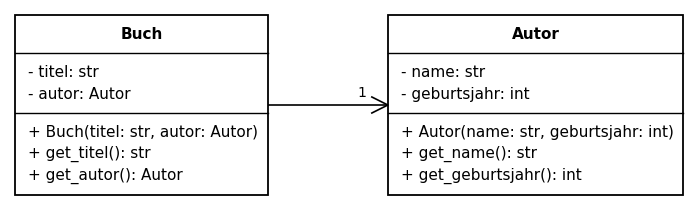



In [ ]:
class Autor:
    def __init__(self, name, geburtsjahr):
        self.__name = name
        self.__geburtsjahr = geburtsjahr

    def get_name(self):
        return self.__name

    def get_geburtsjahr(self):
        return self.__geburtsjahr

class Buch:
    def __init__(self, titel, autor):
        self.__titel = titel
        self.__autor = autor

    def get_titel(self):
        return self.__titel

    def get_autor(self):
        return self.__autor

ende = Autor('Michael Ende', 1929)
momo = Buch('Momo', ende)
print(momo.get_titel())
print(momo.get_autor().get_name())

#### Mehrere Objekte kennen dasselbe Objekt

Zwei Bücher können **dasselbe** Autor-Objekt kennen. Es gibt den Autor dann nur einmal; beide Bücher verweisen darauf (siehe Referenzen im ersten Notebook).

Eine Methode kann die Arbeit an das bekannte Objekt **weitergeben** (*Delegation*): `info()` fragt den Autor nach seinem Namen.

In [ ]:
class Autor:
    def __init__(self, name, geburtsjahr):
        self.__name = name
        self.__geburtsjahr = geburtsjahr

    def get_name(self):
        return self.__name

    def get_geburtsjahr(self):
        return self.__geburtsjahr

class Buch:
    def __init__(self, titel, autor):
        self.__titel = titel
        self.__autor = autor

    def info(self):
        return f'{self.__titel} von {self.__autor.get_name()}'

ende = Autor('Michael Ende', 1929)
b1 = Buch('Momo', ende)
b2 = Buch('Jim Knopf', ende)
print(b1.info())
print(b2.info())

#### Aufgabe 1.1

Erzeuge den Autor Cornelia Funke (geboren 1958) und mit ihm das Buch „Tintenherz“. Gib über das Buch den Namen und das Geburtsjahr des Autors aus.

**Erwartete Ausgabe:**
```
Cornelia Funke
1958
```

In [ ]:
class Autor:
    def __init__(self, name, geburtsjahr):
        self.__name = name
        self.__geburtsjahr = geburtsjahr

    def get_name(self):
        return self.__name

    def get_geburtsjahr(self):
        return self.__geburtsjahr

class Buch:
    def __init__(self, titel, autor):
        self.__titel = titel
        self.__autor = autor

    def get_autor(self):
        return self.__autor
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Autor:
    def __init__(self, name, geburtsjahr):
        self.__name = name
        self.__geburtsjahr = geburtsjahr

    def get_name(self):
        return self.__name

    def get_geburtsjahr(self):
        return self.__geburtsjahr

class Buch:
    def __init__(self, titel, autor):
        self.__titel = titel
        self.__autor = autor

    def get_autor(self):
        return self.__autor

funke = Autor('Cornelia Funke', 1958)
b = Buch('Tintenherz', funke)
print(b.get_autor().get_name())
print(b.get_autor().get_geburtsjahr())
```

</details>

#### Aufgabe 1.2

Ergänze die Klasse `Buch` um eine Methode `info()`, die `Tintenherz (Cornelia Funke, *1958)` zurückgibt. Sie fragt den Autor nach Namen und Geburtsjahr.

**Erwartete Ausgabe:**
```
Tintenherz (Cornelia Funke, *1958)
```

In [ ]:
class Autor:
    def __init__(self, name, geburtsjahr):
        self.__name = name
        self.__geburtsjahr = geburtsjahr

    def get_name(self):
        return self.__name

    def get_geburtsjahr(self):
        return self.__geburtsjahr

class Buch:
    def __init__(self, titel, autor):
        self.__titel = titel
        self.__autor = autor
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Autor:
    def __init__(self, name, geburtsjahr):
        self.__name = name
        self.__geburtsjahr = geburtsjahr

    def get_name(self):
        return self.__name

    def get_geburtsjahr(self):
        return self.__geburtsjahr

class Buch:
    def __init__(self, titel, autor):
        self.__titel = titel
        self.__autor = autor

    def info(self):
        a = self.__autor
        return f'{self.__titel} ({a.get_name()}, *{a.get_geburtsjahr()})'

print(Buch('Tintenherz', Autor('Cornelia Funke', 1958)).info())
```

</details>

#### Aufgabe 1.3

Setze die beiden Klassen aus dem Diagramm um. `vorstellen()` gibt `Ich bin Ali und mein Hund heißt Bello.` zurück.
Erzeuge den Hund und den Besitzer und gib die Vorstellung aus.

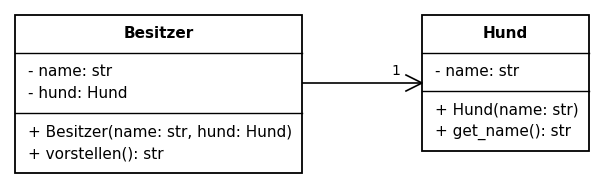



**Erwartete Ausgabe:**
```
Ich bin Ali und mein Hund heißt Bello.
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Hund:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Besitzer:
    def __init__(self, name, hund):
        self.__name = name
        self.__hund = hund

    def vorstellen(self):
        return f'Ich bin {self.__name} und mein Hund heißt {self.__hund.get_name()}.'

bello = Hund('Bello')
ali = Besitzer('Ali', bello)
print(ali.vorstellen())
```

</details>

#### Aufgabe 1.4

Setze die Klassen um. Ein Auto hat einen Motor. `fahren(km)` erhöht den Kilometerstand des Autos und lässt den Motor `laufen(stunden)`, wobei
für die Stunden `km / 50` gerechnet wird. Der Motor zählt seine Betriebsstunden. Fahre 100 km und dann 25 km und gib Kilometerstand und Betriebsstunden aus.

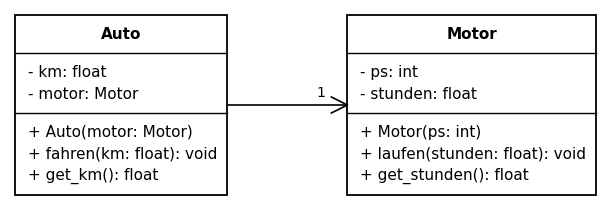



**Erwartete Ausgabe:**
```
125 2.5
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Motor:
    def __init__(self, ps):
        self.__ps = ps
        self.__stunden = 0

    def laufen(self, stunden):
        self.__stunden += stunden

    def get_stunden(self):
        return self.__stunden

class Auto:
    def __init__(self, motor):
        self.__km = 0
        self.__motor = motor

    def fahren(self, km):
        self.__km += km
        self.__motor.laufen(km / 50)

    def get_km(self):
        return self.__km

m = Motor(110)
a = Auto(m)
a.fahren(100)
a.fahren(25)
print(a.get_km(), m.get_stunden())
```

</details>

#### Aufgabe 1.5

Zwei Bücher haben **denselben** Autor. Ändere über das erste Buch den Namen des Autors mit `set_name()` auf `Michael A. H. Ende`
und gib danach den Autor des zweiten Buchs aus.

**Erwartete Ausgabe:**
```
Michael A. H. Ende
```

In [ ]:
class Autor:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

    def set_name(self, name):
        self.__name = name

class Buch:
    def __init__(self, titel, autor):
        self.__titel = titel
        self.__autor = autor

    def get_autor(self):
        return self.__autor

ende = Autor('Michael Ende')
b1 = Buch('Momo', ende)
b2 = Buch('Jim Knopf', ende)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Autor:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

    def set_name(self, name):
        self.__name = name

class Buch:
    def __init__(self, titel, autor):
        self.__titel = titel
        self.__autor = autor

    def get_autor(self):
        return self.__autor

ende = Autor('Michael Ende')
b1 = Buch('Momo', ende)
b2 = Buch('Jim Knopf', ende)
b1.get_autor().set_name('Michael A. H. Ende')
print(b2.get_autor().get_name())
```

</details>

#### Aufgabe 1.6

Setze die Klassen um. Ein Kurs hat eine Lehrkraft. `beschreibung()` gibt `Informatik bei Frau Weber (Raum 204)` zurück; der Raum steht bei der Lehrkraft.
Erzeuge die Lehrkraft und zwei Kurse (Informatik und Mathe) und gib die Beschreibungen aus. Ziehe dann die Lehrkraft mit `set_raum()` in Raum 101 um
und gib die Beschreibungen erneut aus.

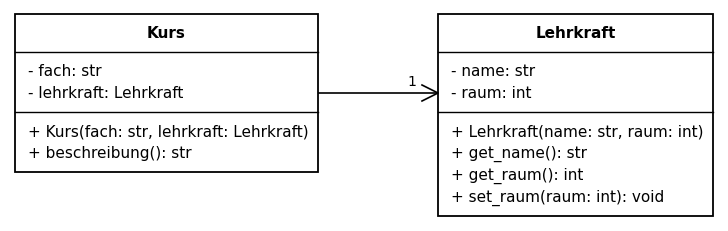



**Erwartete Ausgabe:**
```
Informatik bei Frau Weber (Raum 204)
Mathe bei Frau Weber (Raum 204)
Informatik bei Frau Weber (Raum 101)
Mathe bei Frau Weber (Raum 101)
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Lehrkraft:
    def __init__(self, name, raum):
        self.__name = name
        self.__raum = raum

    def get_name(self):
        return self.__name

    def get_raum(self):
        return self.__raum

    def set_raum(self, raum):
        self.__raum = raum

class Kurs:
    def __init__(self, fach, lehrkraft):
        self.__fach = fach
        self.__lehrkraft = lehrkraft

    def beschreibung(self):
        l = self.__lehrkraft
        return f'{self.__fach} bei {l.get_name()} (Raum {l.get_raum()})'

weber = Lehrkraft('Frau Weber', 204)
kurse = [Kurs('Informatik', weber), Kurs('Mathe', weber)]
for k in kurse:
    print(k.beschreibung())
weber.set_raum(101)
for k in kurse:
    print(k.beschreibung())
```

</details>

#### Aufgabe 1.7

Ergänze die Klasse `Buch` um eine Methode `alter_des_autors()`, die zurückgibt, wie alt der Autor im Erscheinungsjahr des Buches war.
Gib das für „Momo“ (1973) und „Tintenherz“ (2003) aus.

**Erwartete Ausgabe:**
```
44
45
```

In [ ]:
class Autor:
    def __init__(self, name, geburtsjahr):
        self.__name = name
        self.__geburtsjahr = geburtsjahr

    def get_name(self):
        return self.__name

    def get_geburtsjahr(self):
        return self.__geburtsjahr

class Buch:
    def __init__(self, titel, jahr, autor):
        self.__titel = titel
        self.__jahr = jahr
        self.__autor = autor
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Autor:
    def __init__(self, name, geburtsjahr):
        self.__name = name
        self.__geburtsjahr = geburtsjahr

    def get_name(self):
        return self.__name

    def get_geburtsjahr(self):
        return self.__geburtsjahr

class Buch:
    def __init__(self, titel, jahr, autor):
        self.__titel = titel
        self.__jahr = jahr
        self.__autor = autor

    def alter_des_autors(self):
        return self.__jahr - self.__autor.get_geburtsjahr()

print(Buch('Momo', 1973, Autor('Michael Ende', 1929)).alter_des_autors())
print(Buch('Tintenherz', 2003, Autor('Cornelia Funke', 1958)).alter_des_autors())
```

</details>

#### Aufgabe 1.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class A:
    def __init__(self, wert):
        self.wert = wert

class B:
    def __init__(self, a):
        self.a = a

    def doppelt(self):
        return 2 * self.a.wert

a = A(3)
b1 = B(a)
b2 = B(a)
a.wert = 5
print(b1.doppelt(), b2.doppelt())

#### Aufgabe 1.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class A:
    def __init__(self, wert):
        self.wert = wert

class B:
    def __init__(self, a):
        self.a = a

a = A(1)
b = B(a)
a = A(2)
print(b.a.wert, a.wert)

## 2. Optionale Beziehungen: 0..1

#### Ein Objekt, das es nicht immer gibt

Die Multiplizität **0..1** bedeutet: Es gibt **höchstens ein** verbundenes Objekt, vielleicht aber auch keins.
In Python steht dann `None` im Attribut. Mit einem Setter kann man die Beziehung später herstellen oder wieder lösen (`None` setzen).
Vor dem Benutzen prüft man mit `is None`, ob es das Objekt gibt.

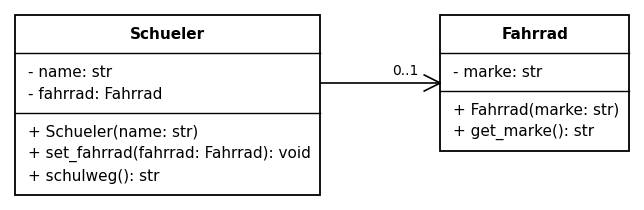



In [ ]:
class Fahrrad:
    def __init__(self, marke):
        self.__marke = marke

    def get_marke(self):
        return self.__marke

class Schueler:
    def __init__(self, name):
        self.__name = name
        self.__fahrrad = None

    def set_fahrrad(self, fahrrad):
        self.__fahrrad = fahrrad

    def schulweg(self):
        if self.__fahrrad is None:
            return f'{self.__name} geht zu Fuß'
        return f'{self.__name} fährt mit dem {self.__fahrrad.get_marke()}-Rad'

ali = Schueler('Ali')
print(ali.schulweg())
ali.set_fahrrad(Fahrrad('Cube'))
print(ali.schulweg())
ali.set_fahrrad(None)
print(ali.schulweg())

#### Aufgabe 2.1

Setze die Klassen um. Ein Spieler hat höchstens eine Waffe. `angriff()` gibt `1` zurück, wenn der Spieler keine Waffe hat, sonst den Schaden der Waffe.
Gib den Angriff ohne Waffe aus, gib dem Spieler ein Schwert mit Schaden 7 und gib den Angriff erneut aus.

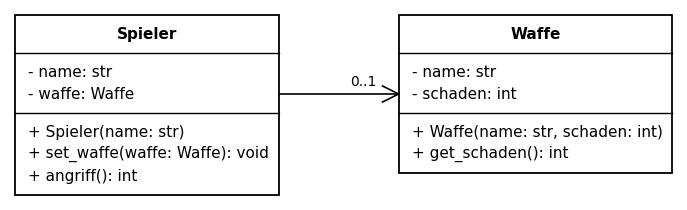



**Erwartete Ausgabe:**
```
1
7
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Waffe:
    def __init__(self, name, schaden):
        self.__name = name
        self.__schaden = schaden

    def get_schaden(self):
        return self.__schaden

class Spieler:
    def __init__(self, name):
        self.__name = name
        self.__waffe = None

    def set_waffe(self, waffe):
        self.__waffe = waffe

    def angriff(self):
        if self.__waffe is None:
            return 1
        return self.__waffe.get_schaden()

s = Spieler('Luna')
print(s.angriff())
s.set_waffe(Waffe('Schwert', 7))
print(s.angriff())
```

</details>

#### Aufgabe 2.2

Ergänze die Klasse `Sitzplatz` um `buchen(person)` (gibt `False` zurück, wenn der Platz schon belegt ist), `freigeben()` und `__str__`
(`12: frei` oder `12: Bea`). Buche Platz 12 für Bea, versuche ihn für Cem zu buchen, gib ihn aus, gib ihn frei und gib ihn wieder aus.

**Erwartete Ausgabe:**
```
True
False
12: Bea
12: frei
```

In [ ]:
class Person:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Sitzplatz:
    def __init__(self, nr):
        self.__nr = nr
        self.__person = None
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Person:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Sitzplatz:
    def __init__(self, nr):
        self.__nr = nr
        self.__person = None

    def buchen(self, person):
        if self.__person is not None:
            return False
        self.__person = person
        return True

    def freigeben(self):
        self.__person = None

    def __str__(self):
        if self.__person is None:
            return f'{self.__nr}: frei'
        return f'{self.__nr}: {self.__person.get_name()}'

p = Sitzplatz(12)
print(p.buchen(Person('Bea')))
print(p.buchen(Person('Cem')))
print(p)
p.freigeben()
print(p)
```

</details>

#### Aufgabe 2.3

Ein Raum hat höchstens einen Beamer. Gib für jeden Raum in `raeume` aus, ob er einen Beamer hat und wenn ja, mit welcher Auflösung, in der Form
`R101: 1920x1080` oder `R102: kein Beamer`.

**Erwartete Ausgabe:**
```
R101: 1920x1080
R102: kein Beamer
R103: 1280x800
```

In [ ]:
class Beamer:
    def __init__(self, aufloesung):
        self.__aufloesung = aufloesung

    def get_aufloesung(self):
        return self.__aufloesung

class Raum:
    def __init__(self, name, beamer=None):
        self.__name = name
        self.__beamer = beamer

    def get_name(self):
        return self.__name

    def get_beamer(self):
        return self.__beamer

raeume = [Raum('R101', Beamer('1920x1080')), Raum('R102'), Raum('R103', Beamer('1280x800'))]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Beamer:
    def __init__(self, aufloesung):
        self.__aufloesung = aufloesung

    def get_aufloesung(self):
        return self.__aufloesung

class Raum:
    def __init__(self, name, beamer=None):
        self.__name = name
        self.__beamer = beamer

    def get_name(self):
        return self.__name

    def get_beamer(self):
        return self.__beamer

raeume = [Raum('R101', Beamer('1920x1080')), Raum('R102'), Raum('R103', Beamer('1280x800'))]
for r in raeume:
    b = r.get_beamer()
    if b is None:
        print(f'{r.get_name()}: kein Beamer')
    else:
        print(f'{r.get_name()}: {b.get_aufloesung()}')
```

</details>

#### Aufgabe 2.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Ziel:
    def __init__(self, n):
        self.n = n

class Quelle:
    def __init__(self):
        self.ziel = None

    def wert(self):
        if self.ziel is None:
            return 0
        return self.ziel.n

q = Quelle()
print(q.wert())
q.ziel = Ziel(4)
print(q.wert())
q.ziel.n += 1
print(q.wert())

#### Aufgabe 2.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Quelle:
    def __init__(self):
        self.ziel = None

q = Quelle()
print(q.ziel.n)

## 3. Viele Objekte: 0..* mit einer Liste

#### Eine Klasse kennt viele Objekte

Kennt ein Objekt **beliebig viele** andere, speichert es sie in einer **Liste**. Im Diagramm steht dann `0..*` (keins oder beliebig viele)
am Pfeil, als Typ des Attributs `list`.

Typische Methoden einer solchen Klasse: `hinzufuegen()`, `entfernen()`, `anzahl()`, Suchen und Auswerten über alle Objekte der Liste.
Die Liste selbst gibt man nicht heraus (sonst könnte man sie von außen verändern).

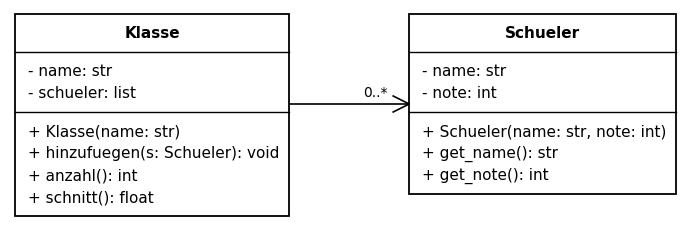



In [ ]:
class Schueler:
    def __init__(self, name, note):
        self.__name = name
        self.__note = note

    def get_name(self):
        return self.__name

    def get_note(self):
        return self.__note

class Klasse:
    def __init__(self, name):
        self.__name = name
        self.__schueler = []

    def hinzufuegen(self, s):
        self.__schueler.append(s)

    def anzahl(self):
        return len(self.__schueler)

    def schnitt(self):
        summe = 0
        for s in self.__schueler:
            summe += s.get_note()
        return summe / len(self.__schueler)

k = Klasse('9a')
k.hinzufuegen(Schueler('Ali', 2))
k.hinzufuegen(Schueler('Bea', 1))
k.hinzufuegen(Schueler('Cem', 3))
print(k.anzahl(), k.schnitt())

#### Aufgabe 3.1

Setze die beiden Klassen aus dem Diagramm um und ergänze `Playlist` um `anzahl()`. Füge drei Songs hinzu und gib die Anzahl aus.

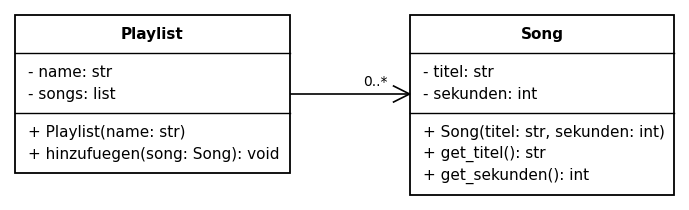



**Erwartete Ausgabe:**
```
3
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Song:
    def __init__(self, titel, sekunden):
        self.__titel = titel
        self.__sekunden = sekunden

    def get_titel(self):
        return self.__titel

    def get_sekunden(self):
        return self.__sekunden

class Playlist:
    def __init__(self, name):
        self.__name = name
        self.__songs = []

    def hinzufuegen(self, song):
        self.__songs.append(song)

    def anzahl(self):
        return len(self.__songs)

p = Playlist('Lieblingslieder')
p.hinzufuegen(Song('Atemlos', 230))
p.hinzufuegen(Song('Happy', 233))
p.hinzufuegen(Song('Hallelujah', 270))
print(p.anzahl())
```

</details>

#### Aufgabe 3.2

Ergänze `Playlist` um `gesamtdauer()`, die die Dauer aller Songs als Text `mm:ss` zurückgibt. Gib die Gesamtdauer der Playlist aus.

**Erwartete Ausgabe:**
```
14:54
```

In [ ]:
class Song:
    def __init__(self, titel, sekunden):
        self.__titel = titel
        self.__sekunden = sekunden

    def get_titel(self):
        return self.__titel

    def get_sekunden(self):
        return self.__sekunden

class Playlist:
    def __init__(self, name):
        self.__name = name
        self.__songs = []

    def hinzufuegen(self, song):
        self.__songs.append(song)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Song:
    def __init__(self, titel, sekunden):
        self.__titel = titel
        self.__sekunden = sekunden

    def get_titel(self):
        return self.__titel

    def get_sekunden(self):
        return self.__sekunden

class Playlist:
    def __init__(self, name):
        self.__name = name
        self.__songs = []

    def hinzufuegen(self, song):
        self.__songs.append(song)


    def gesamtdauer(self):
        summe = 0
        for s in self.__songs:
            summe += s.get_sekunden()
        return f'{summe // 60:02d}:{summe % 60:02d}'

p = Playlist('Sport')
for titel, sek in [('Eye of the Tiger', 245), ('Run', 210), ('Jump', 241), ('Shout', 198)]:
    p.hinzufuegen(Song(titel, sek))
print(p.gesamtdauer())
```

</details>

#### Aufgabe 3.3

Ergänze `Playlist` um `titel()`, die eine Liste aller Songtitel zurückgibt, und `laengster()`, die den Titel des längsten Songs zurückgibt. Gib beides aus.

**Erwartete Ausgabe:**
```
['Eye of the Tiger', 'Run', 'Jump', 'Shout']
Eye of the Tiger
```

In [ ]:
class Song:
    def __init__(self, titel, sekunden):
        self.__titel = titel
        self.__sekunden = sekunden

    def get_titel(self):
        return self.__titel

    def get_sekunden(self):
        return self.__sekunden

class Playlist:
    def __init__(self, name):
        self.__name = name
        self.__songs = []

    def hinzufuegen(self, song):
        self.__songs.append(song)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Song:
    def __init__(self, titel, sekunden):
        self.__titel = titel
        self.__sekunden = sekunden

    def get_titel(self):
        return self.__titel

    def get_sekunden(self):
        return self.__sekunden

class Playlist:
    def __init__(self, name):
        self.__name = name
        self.__songs = []

    def hinzufuegen(self, song):
        self.__songs.append(song)


    def titel(self):
        ergebnis = []
        for s in self.__songs:
            ergebnis.append(s.get_titel())
        return ergebnis

    def laengster(self):
        return max(self.__songs, key=lambda s: s.get_sekunden()).get_titel()

p = Playlist('Sport')
for titel, sek in [('Eye of the Tiger', 245), ('Run', 210), ('Jump', 241), ('Shout', 198)]:
    p.hinzufuegen(Song(titel, sek))
print(p.titel())
print(p.laengster())
```

</details>

#### Aufgabe 3.4

Ergänze `Playlist` um `suche(titel)`, die den Song mit diesem Titel zurückgibt oder `None`, und `entfernen(titel)`, die ihn mit `remove()` aus der Liste
entfernt und `True` zurückgibt (`False`, wenn es ihn nicht gibt). Entferne `Run` und `Thriller` und gib danach die Anzahl der Songs aus.

**Erwartete Ausgabe:**
```
True
False
3
```

In [ ]:
class Song:
    def __init__(self, titel, sekunden):
        self.__titel = titel
        self.__sekunden = sekunden

    def get_titel(self):
        return self.__titel

    def get_sekunden(self):
        return self.__sekunden

class Playlist:
    def __init__(self, name):
        self.__name = name
        self.__songs = []

    def hinzufuegen(self, song):
        self.__songs.append(song)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Song:
    def __init__(self, titel, sekunden):
        self.__titel = titel
        self.__sekunden = sekunden

    def get_titel(self):
        return self.__titel

    def get_sekunden(self):
        return self.__sekunden

class Playlist:
    def __init__(self, name):
        self.__name = name
        self.__songs = []

    def hinzufuegen(self, song):
        self.__songs.append(song)


    def suche(self, titel):
        for s in self.__songs:
            if s.get_titel() == titel:
                return s
        return None

    def entfernen(self, titel):
        s = self.suche(titel)
        if s is None:
            return False
        self.__songs.remove(s)
        return True

    def anzahl(self):
        return len(self.__songs)

p = Playlist('Sport')
for titel, sek in [('Eye of the Tiger', 245), ('Run', 210), ('Jump', 241), ('Shout', 198)]:
    p.hinzufuegen(Song(titel, sek))
print(p.entfernen('Run'))
print(p.entfernen('Thriller'))
print(p.anzahl())
```

</details>

#### Aufgabe 3.5

Ergänze `Playlist` um `kurze_songs(maximal)`, die eine neue Playlist mit dem Namen `kurz` zurückgibt, in der nur die Songs mit höchstens `maximal` Sekunden stehen. Gib die Titel der neuen Playlist aus.

**Erwartete Ausgabe:**
```
['Run', 'Shout']
```

In [ ]:
class Song:
    def __init__(self, titel, sekunden):
        self.__titel = titel
        self.__sekunden = sekunden

    def get_titel(self):
        return self.__titel

    def get_sekunden(self):
        return self.__sekunden

class Playlist:
    def __init__(self, name):
        self.__name = name
        self.__songs = []

    def hinzufuegen(self, song):
        self.__songs.append(song)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Song:
    def __init__(self, titel, sekunden):
        self.__titel = titel
        self.__sekunden = sekunden

    def get_titel(self):
        return self.__titel

    def get_sekunden(self):
        return self.__sekunden

class Playlist:
    def __init__(self, name):
        self.__name = name
        self.__songs = []

    def hinzufuegen(self, song):
        self.__songs.append(song)


    def kurze_songs(self, maximal):
        neu = Playlist('kurz')
        for s in self.__songs:
            if s.get_sekunden() <= maximal:
                neu.hinzufuegen(s)
        return neu

    def titel(self):
        ergebnis = []
        for s in self.__songs:
            ergebnis.append(s.get_titel())
        return ergebnis

p = Playlist('Sport')
for titel, sek in [('Eye of the Tiger', 245), ('Run', 210), ('Jump', 241), ('Shout', 198)]:
    p.hinzufuegen(Song(titel, sek))
print(p.kurze_songs(220).titel())
```

</details>

#### Aufgabe 3.6

Setze die Klassen um. Ein Warenkorb enthält Positionen; eine Position besteht aus einem Artikelnamen, einem Einzelpreis und einer Menge.
`get_summe()` der Position gibt Preis mal Menge zurück, `gesamt()` des Warenkorbs die Summe aller Positionen. Ist ein Artikel schon im Korb, erhöht
`hinzufuegen()` nur die Menge der vorhandenen Position. Lege 2× Heft (1.20), 1× Mappe (2.50) und noch 3× Heft hinein. Gib die Anzahl der Positionen und
die Gesamtsumme mit zwei Nachkommastellen aus.

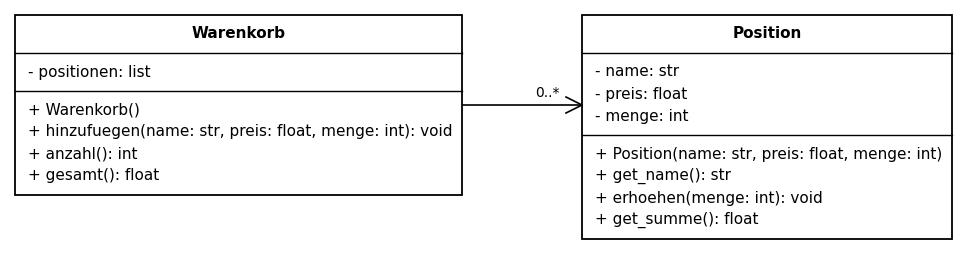



**Erwartete Ausgabe:**
```
2
8.50
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Position:
    def __init__(self, name, preis, menge):
        self.__name = name
        self.__preis = preis
        self.__menge = menge

    def get_name(self):
        return self.__name

    def erhoehen(self, menge):
        self.__menge += menge

    def get_summe(self):
        return self.__preis * self.__menge

class Warenkorb:
    def __init__(self):
        self.__positionen = []

    def hinzufuegen(self, name, preis, menge):
        for p in self.__positionen:
            if p.get_name() == name:
                p.erhoehen(menge)
                return
        self.__positionen.append(Position(name, preis, menge))

    def anzahl(self):
        return len(self.__positionen)

    def gesamt(self):
        summe = 0
        for p in self.__positionen:
            summe += p.get_summe()
        return summe

w = Warenkorb()
w.hinzufuegen('Heft', 1.20, 2)
w.hinzufuegen('Mappe', 2.50, 1)
w.hinzufuegen('Heft', 1.20, 3)
print(w.anzahl())
print(f'{w.gesamt():.2f}')
```

</details>

#### Aufgabe 3.7

Ein Stall hat höchstens `plaetze` Pferde. `einstellen(pferd)` gibt `False` zurück, wenn der Stall voll ist oder das Pferd schon darin steht
(`in` vergleicht hier die Objekte selbst). Gib nach jedem Versuch das Ergebnis aus und zum Schluss die Namen der Pferde.

**Erwartete Ausgabe:**
```
True
False
True
False
['Fury', 'Black Beauty']
```

In [ ]:
class Pferd:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Stall:
    def __init__(self, plaetze):
        self.__plaetze = plaetze
        self.__pferde = []
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Pferd:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Stall:
    def __init__(self, plaetze):
        self.__plaetze = plaetze
        self.__pferde = []

    def einstellen(self, pferd):
        if len(self.__pferde) >= self.__plaetze or pferd in self.__pferde:
            return False
        self.__pferde.append(pferd)
        return True

    def namen(self):
        ergebnis = []
        for p in self.__pferde:
            ergebnis.append(p.get_name())
        return ergebnis

stall = Stall(2)
fury = Pferd('Fury')
print(stall.einstellen(fury))
print(stall.einstellen(fury))
print(stall.einstellen(Pferd('Black Beauty')))
print(stall.einstellen(Pferd('Spirit')))
print(stall.namen())
```

</details>

#### Aufgabe 3.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Teil:
    def __init__(self, n):
        self.n = n

class Sammlung:
    def __init__(self):
        self.teile = []

    def dazu(self, t):
        self.teile.append(t)

    def summe(self):
        s = 0
        for t in self.teile:
            s += t.n
        return s

x = Teil(5)
s = Sammlung()
s.dazu(x)
s.dazu(Teil(2))
s.dazu(x)
x.n = 1
print(len(s.teile), s.summe())

## 4. Beziehungen in beide Richtungen

#### Beide Seiten kennen sich

Manchmal sollen sich beide Objekte gegenseitig kennen: Die Klasse kennt ihre Schüler, und jeder Schüler kennt seine Klasse.
Im Diagramm ist das eine Linie **ohne Pfeilspitze**, mit einer Multiplizität an jedem Ende.

Dann muss man darauf achten, dass **beide Seiten zusammenpassen**. Am sichersten ist es, wenn **eine** Methode beide Seiten setzt:
`klasse.aufnehmen(s)` hängt den Schüler an die Liste an **und** setzt beim Schüler die Klasse.

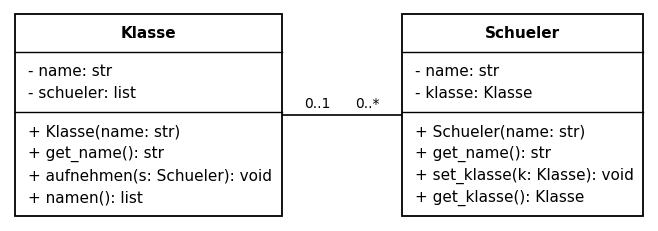



In [ ]:
class Schueler:
    def __init__(self, name):
        self.__name = name
        self.__klasse = None

    def get_name(self):
        return self.__name

    def set_klasse(self, klasse):
        self.__klasse = klasse

    def get_klasse(self):
        return self.__klasse

class Klasse:
    def __init__(self, name):
        self.__name = name
        self.__schueler = []

    def get_name(self):
        return self.__name

    def aufnehmen(self, s):
        self.__schueler.append(s)
        s.set_klasse(self)

    def namen(self):
        ergebnis = []
        for s in self.__schueler:
            ergebnis.append(s.get_name())
        return ergebnis

k = Klasse('9a')
ali = Schueler('Ali')
k.aufnehmen(ali)
k.aufnehmen(Schueler('Bea'))
print(k.namen())
print(ali.get_klasse().get_name())

#### Aufgabe 4.1

Ergänze die Klasse `Team` um `aufnehmen(spieler)`, die beide Seiten der Beziehung setzt. Nimm Mia und Ida ins Team `Blau` auf und gib für beide den Teamnamen aus.

**Erwartete Ausgabe:**
```
Blau Blau
```

In [ ]:
class Spieler:
    def __init__(self, name):
        self.__name = name
        self.__team = None

    def get_name(self):
        return self.__name

    def set_team(self, team):
        self.__team = team

    def get_team(self):
        return self.__team

class Team:
    def __init__(self, name):
        self.__name = name
        self.__spieler = []

    def get_name(self):
        return self.__name
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Spieler:
    def __init__(self, name):
        self.__name = name
        self.__team = None

    def get_name(self):
        return self.__name

    def set_team(self, team):
        self.__team = team

    def get_team(self):
        return self.__team

class Team:
    def __init__(self, name):
        self.__name = name
        self.__spieler = []

    def get_name(self):
        return self.__name


    def aufnehmen(self, spieler):
        self.__spieler.append(spieler)
        spieler.set_team(self)

blau = Team('Blau')
mia = Spieler('Mia')
ida = Spieler('Ida')
blau.aufnehmen(mia)
blau.aufnehmen(ida)
print(mia.get_team().get_name(), ida.get_team().get_name())
```

</details>

#### Aufgabe 4.2

Ergänze die Klasse `Team` um `aufnehmen()` und `entlassen(spieler)`: Entfernt den Spieler aus der Liste und setzt sein Team auf `None`. Ergänze außerdem `groesse()`.
Nimm Mia und Ida auf, entlasse Mia, gib die Teamgröße aus und ob Mia noch ein Team hat.

**Erwartete Ausgabe:**
```
1
True
```

In [ ]:
class Spieler:
    def __init__(self, name):
        self.__name = name
        self.__team = None

    def get_name(self):
        return self.__name

    def set_team(self, team):
        self.__team = team

    def get_team(self):
        return self.__team

class Team:
    def __init__(self, name):
        self.__name = name
        self.__spieler = []

    def get_name(self):
        return self.__name
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Spieler:
    def __init__(self, name):
        self.__name = name
        self.__team = None

    def get_name(self):
        return self.__name

    def set_team(self, team):
        self.__team = team

    def get_team(self):
        return self.__team

class Team:
    def __init__(self, name):
        self.__name = name
        self.__spieler = []

    def get_name(self):
        return self.__name


    def aufnehmen(self, spieler):
        self.__spieler.append(spieler)
        spieler.set_team(self)

    def entlassen(self, spieler):
        self.__spieler.remove(spieler)
        spieler.set_team(None)

    def groesse(self):
        return len(self.__spieler)

blau = Team('Blau')
mia = Spieler('Mia')
ida = Spieler('Ida')
blau.aufnehmen(mia)
blau.aufnehmen(ida)
blau.entlassen(mia)
print(blau.groesse())
print(mia.get_team() is None)
```

</details>

#### Aufgabe 4.3

Ein Spieler wechselt das Team: Ergänze `Team` um `aufnehmen()` und `entlassen()` (wie in der Aufgabe davor). `aufnehmen()` soll den Spieler
**vorher** aus seinem alten Team entlassen, falls er eins hat. Nimm Mia ins Team Blau auf und dann ins Team Rot. Gib die Größen beider Teams und Mias Team aus.

**Erwartete Ausgabe:**
```
0 1
Rot
```

In [ ]:
class Spieler:
    def __init__(self, name):
        self.__name = name
        self.__team = None

    def get_name(self):
        return self.__name

    def set_team(self, team):
        self.__team = team

    def get_team(self):
        return self.__team

class Team:
    def __init__(self, name):
        self.__name = name
        self.__spieler = []

    def get_name(self):
        return self.__name
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Spieler:
    def __init__(self, name):
        self.__name = name
        self.__team = None

    def get_name(self):
        return self.__name

    def set_team(self, team):
        self.__team = team

    def get_team(self):
        return self.__team

class Team:
    def __init__(self, name):
        self.__name = name
        self.__spieler = []

    def get_name(self):
        return self.__name


    def aufnehmen(self, spieler):
        alt = spieler.get_team()
        if alt is not None:
            alt.entlassen(spieler)
        self.__spieler.append(spieler)
        spieler.set_team(self)

    def entlassen(self, spieler):
        self.__spieler.remove(spieler)
        spieler.set_team(None)

    def groesse(self):
        return len(self.__spieler)

blau = Team('Blau')
rot = Team('Rot')
mia = Spieler('Mia')
blau.aufnehmen(mia)
rot.aufnehmen(mia)
print(blau.groesse(), rot.groesse())
print(mia.get_team().get_name())
```

</details>

#### Aufgabe 4.4

Setze die Klassen um (eine Person hat höchstens einen Ausweis, ein Ausweis gehört genau einer Person). Der Konstruktor von `Ausweis` bekommt die Person
und trägt sich selbst bei ihr ein (`person.set_ausweis(self)`). Erzeuge Ali und seinen Ausweis mit der Nummer `L01X7`; gib über die Person die
Ausweisnummer aus und über den Ausweis den Namen der Person.

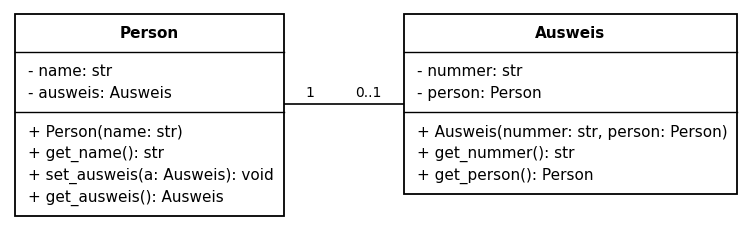



**Erwartete Ausgabe:**
```
L01X7
Ali
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Person:
    def __init__(self, name):
        self.__name = name
        self.__ausweis = None

    def get_name(self):
        return self.__name

    def set_ausweis(self, a):
        self.__ausweis = a

    def get_ausweis(self):
        return self.__ausweis

class Ausweis:
    def __init__(self, nummer, person):
        self.__nummer = nummer
        self.__person = person
        person.set_ausweis(self)

    def get_nummer(self):
        return self.__nummer

    def get_person(self):
        return self.__person

ali = Person('Ali')
a = Ausweis('L01X7', ali)
print(ali.get_ausweis().get_nummer())
print(a.get_person().get_name())
```

</details>

#### Aufgabe 4.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class A:
    def __init__(self):
        self.b = None

class B:
    def __init__(self, a):
        self.a = a
        a.b = self

a = A()
b = B(a)
print(a.b is b, b.a is a, a.b.a is a)

## 5. Mehrere Klassen arbeiten zusammen

#### Bibliothek, Buch und Leser

Eine Ausleihe betrifft drei Klassen: Die **Bibliothek** kennt alle Bücher. Ein **Buch** weiß, ob und an wen es ausgeliehen ist (0..1).
Ein **Leser** hat einen Namen. Die Methoden der Bibliothek benutzen die Methoden der anderen Klassen.

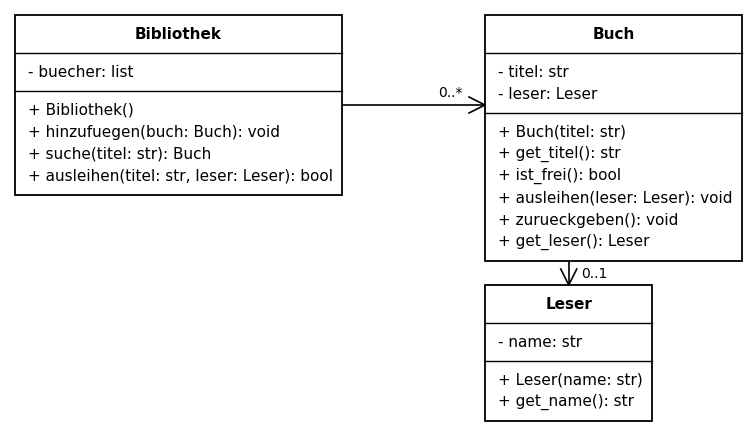



In [ ]:
class Leser:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Buch:
    def __init__(self, titel):
        self.__titel = titel
        self.__leser = None

    def get_titel(self):
        return self.__titel

    def ist_frei(self):
        return self.__leser is None

    def ausleihen(self, leser):
        self.__leser = leser

    def zurueckgeben(self):
        self.__leser = None

    def get_leser(self):
        return self.__leser

class Bibliothek:
    def __init__(self):
        self.__buecher = []

    def hinzufuegen(self, buch):
        self.__buecher.append(buch)

    def suche(self, titel):
        for b in self.__buecher:
            if b.get_titel() == titel:
                return b
        return None

    def ausleihen(self, titel, leser):
        b = self.suche(titel)
        if b is None or not b.ist_frei():
            return False
        b.ausleihen(leser)
        return True

bib = Bibliothek()
for titel in ['Momo', 'Krabat', 'Tschick']:
    bib.hinzufuegen(Buch(titel))
ali = Leser('Ali')
print(bib.ausleihen('Momo', ali))
print(bib.ausleihen('Momo', Leser('Bea')))
print(bib.ausleihen('Emil', ali))
print(bib.suche('Momo').get_leser().get_name())

#### Aufgabe 5.1

Ergänze die Klasse `Bibliothek` um `freie_buecher()`, die die Titel aller nicht ausgeliehenen Bücher als Liste zurückgibt. Gib sie aus.

**Erwartete Ausgabe:**
```
['Tschick']
```

In [ ]:
class Leser:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Buch:
    def __init__(self, titel):
        self.__titel = titel
        self.__leser = None

    def get_titel(self):
        return self.__titel

    def ist_frei(self):
        return self.__leser is None

    def ausleihen(self, leser):
        self.__leser = leser

    def zurueckgeben(self):
        self.__leser = None

    def get_leser(self):
        return self.__leser

class Bibliothek:
    def __init__(self, titel_liste):
        self.__buecher = []
        for t in titel_liste:
            self.__buecher.append(Buch(t))

    def suche(self, titel):
        for b in self.__buecher:
            if b.get_titel() == titel:
                return b
        return None
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Leser:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Buch:
    def __init__(self, titel):
        self.__titel = titel
        self.__leser = None

    def get_titel(self):
        return self.__titel

    def ist_frei(self):
        return self.__leser is None

    def ausleihen(self, leser):
        self.__leser = leser

    def zurueckgeben(self):
        self.__leser = None

    def get_leser(self):
        return self.__leser

class Bibliothek:
    def __init__(self, titel_liste):
        self.__buecher = []
        for t in titel_liste:
            self.__buecher.append(Buch(t))

    def suche(self, titel):
        for b in self.__buecher:
            if b.get_titel() == titel:
                return b
        return None


    def freie_buecher(self):
        ergebnis = []
        for b in self.__buecher:
            if b.ist_frei():
                ergebnis.append(b.get_titel())
        return ergebnis

bib = Bibliothek(['Momo', 'Krabat', 'Tschick', 'Emil'])
ali = Leser('Ali')
bea = Leser('Bea')
bib.suche('Krabat').ausleihen(ali)
bib.suche('Emil').ausleihen(bea)
bib.suche('Momo').ausleihen(ali)
print(bib.freie_buecher())
```

</details>

#### Aufgabe 5.2

Ergänze die Klasse `Bibliothek` um `buecher_von(leser)`, die die Titel aller Bücher zurückgibt, die dieser Leser ausgeliehen hat (Vergleich mit `is`). Gib sie für Ali und für Bea aus.

**Erwartete Ausgabe:**
```
['Momo', 'Krabat']
['Emil']
```

In [ ]:
class Leser:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Buch:
    def __init__(self, titel):
        self.__titel = titel
        self.__leser = None

    def get_titel(self):
        return self.__titel

    def ist_frei(self):
        return self.__leser is None

    def ausleihen(self, leser):
        self.__leser = leser

    def zurueckgeben(self):
        self.__leser = None

    def get_leser(self):
        return self.__leser

class Bibliothek:
    def __init__(self, titel_liste):
        self.__buecher = []
        for t in titel_liste:
            self.__buecher.append(Buch(t))

    def suche(self, titel):
        for b in self.__buecher:
            if b.get_titel() == titel:
                return b
        return None
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Leser:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Buch:
    def __init__(self, titel):
        self.__titel = titel
        self.__leser = None

    def get_titel(self):
        return self.__titel

    def ist_frei(self):
        return self.__leser is None

    def ausleihen(self, leser):
        self.__leser = leser

    def zurueckgeben(self):
        self.__leser = None

    def get_leser(self):
        return self.__leser

class Bibliothek:
    def __init__(self, titel_liste):
        self.__buecher = []
        for t in titel_liste:
            self.__buecher.append(Buch(t))

    def suche(self, titel):
        for b in self.__buecher:
            if b.get_titel() == titel:
                return b
        return None


    def buecher_von(self, leser):
        ergebnis = []
        for b in self.__buecher:
            if b.get_leser() is leser:
                ergebnis.append(b.get_titel())
        return ergebnis

bib = Bibliothek(['Momo', 'Krabat', 'Tschick', 'Emil'])
ali = Leser('Ali')
bea = Leser('Bea')
bib.suche('Krabat').ausleihen(ali)
bib.suche('Emil').ausleihen(bea)
bib.suche('Momo').ausleihen(ali)
print(bib.buecher_von(ali))
print(bib.buecher_von(bea))
```

</details>

#### Aufgabe 5.3

Ergänze die Klasse `Bibliothek` um `zurueckgeben(titel)` (gibt `False` zurück, wenn es das Buch nicht gibt oder es nicht ausgeliehen ist) und
`ausleihliste()`, die für jedes ausgeliehene Buch `Krabat: Ali` als Liste zurückgibt. Gib die Ausleihliste aus, gib Krabat und Tschick zurück (mit Ausgabe des Ergebnisses)
und gib die Liste wieder aus.

**Erwartete Ausgabe:**
```
['Momo: Ali', 'Krabat: Ali', 'Emil: Bea']
True
False
['Momo: Ali', 'Emil: Bea']
```

In [ ]:
class Leser:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Buch:
    def __init__(self, titel):
        self.__titel = titel
        self.__leser = None

    def get_titel(self):
        return self.__titel

    def ist_frei(self):
        return self.__leser is None

    def ausleihen(self, leser):
        self.__leser = leser

    def zurueckgeben(self):
        self.__leser = None

    def get_leser(self):
        return self.__leser

class Bibliothek:
    def __init__(self, titel_liste):
        self.__buecher = []
        for t in titel_liste:
            self.__buecher.append(Buch(t))

    def suche(self, titel):
        for b in self.__buecher:
            if b.get_titel() == titel:
                return b
        return None
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Leser:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Buch:
    def __init__(self, titel):
        self.__titel = titel
        self.__leser = None

    def get_titel(self):
        return self.__titel

    def ist_frei(self):
        return self.__leser is None

    def ausleihen(self, leser):
        self.__leser = leser

    def zurueckgeben(self):
        self.__leser = None

    def get_leser(self):
        return self.__leser

class Bibliothek:
    def __init__(self, titel_liste):
        self.__buecher = []
        for t in titel_liste:
            self.__buecher.append(Buch(t))

    def suche(self, titel):
        for b in self.__buecher:
            if b.get_titel() == titel:
                return b
        return None


    def zurueckgeben(self, titel):
        b = self.suche(titel)
        if b is None or b.ist_frei():
            return False
        b.zurueckgeben()
        return True

    def ausleihliste(self):
        ergebnis = []
        for b in self.__buecher:
            if not b.ist_frei():
                ergebnis.append(f'{b.get_titel()}: {b.get_leser().get_name()}')
        return ergebnis

bib = Bibliothek(['Momo', 'Krabat', 'Tschick', 'Emil'])
ali = Leser('Ali')
bea = Leser('Bea')
bib.suche('Krabat').ausleihen(ali)
bib.suche('Emil').ausleihen(bea)
bib.suche('Momo').ausleihen(ali)
print(bib.ausleihliste())
print(bib.zurueckgeben('Krabat'))
print(bib.zurueckgeben('Tschick'))
print(bib.ausleihliste())
```

</details>

#### Aufgabe 5.4

Setze die drei Klassen um. Eine Schule hat Kurse, ein Kurs hat eine Lehrkraft und eine Liste von Teilnehmernamen.
`kurse_von(name)` der Schule gibt die Fächer aller Kurse der Lehrkraft mit diesem Namen zurück, `groesster_kurs()` das Fach des Kurses mit den meisten Teilnehmern.
Lege die Kurse aus `daten` an und gib `kurse_von('Weber')` und `groesster_kurs()` aus.

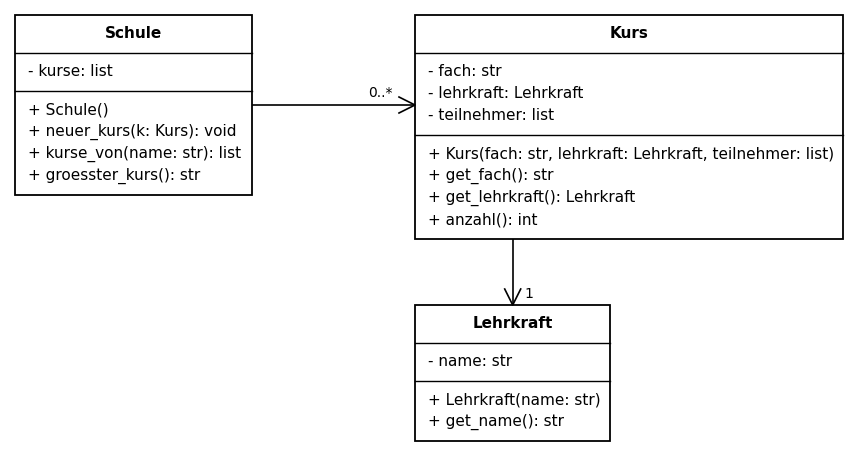



**Erwartete Ausgabe:**
```
['Mathe', 'Informatik']
Informatik
```

In [ ]:
daten = [('Mathe', 'Weber', ['Ali', 'Bea', 'Cem']), ('Physik', 'Kaya', ['Ali', 'Dana']),
         ('Informatik', 'Weber', ['Bea', 'Cem', 'Emil', 'Fiona'])]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
daten = [('Mathe', 'Weber', ['Ali', 'Bea', 'Cem']), ('Physik', 'Kaya', ['Ali', 'Dana']),
         ('Informatik', 'Weber', ['Bea', 'Cem', 'Emil', 'Fiona'])]
class Lehrkraft:
    def __init__(self, name):
        self.__name = name

    def get_name(self):
        return self.__name

class Kurs:
    def __init__(self, fach, lehrkraft, teilnehmer):
        self.__fach = fach
        self.__lehrkraft = lehrkraft
        self.__teilnehmer = teilnehmer

    def get_fach(self):
        return self.__fach

    def get_lehrkraft(self):
        return self.__lehrkraft

    def anzahl(self):
        return len(self.__teilnehmer)

class Schule:
    def __init__(self):
        self.__kurse = []

    def neuer_kurs(self, k):
        self.__kurse.append(k)

    def kurse_von(self, name):
        ergebnis = []
        for k in self.__kurse:
            if k.get_lehrkraft().get_name() == name:
                ergebnis.append(k.get_fach())
        return ergebnis

    def groesster_kurs(self):
        return max(self.__kurse, key=lambda k: k.anzahl()).get_fach()

lehrkraefte = {}
schule = Schule()
for fach, name, teilnehmer in daten:
    if name not in lehrkraefte:
        lehrkraefte[name] = Lehrkraft(name)
    schule.neuer_kurs(Kurs(fach, lehrkraefte[name], teilnehmer))
print(schule.kurse_von('Weber'))
print(schule.groesster_kurs())
```

</details>

#### Aufgabe 5.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Leser:
    def __init__(self, name):
        self.name = name

class Buch:
    def __init__(self):
        self.leser = None

a = Leser('Ali')
b1 = Buch()
b2 = Buch()
b1.leser = a
b2.leser = b1.leser
b1.leser = None
a.name = 'Bea'
print(b1.leser is None, b2.leser.name)

## 6. Rekursive Assoziation

#### Eine Klasse kennt Objekte der eigenen Klasse

Bei einer **rekursiven Assoziation** verweist ein Objekt auf ein Objekt **derselben** Klasse: Ein Mitarbeiter hat einen Chef, der selbst
ein Mitarbeiter ist. Im Diagramm geht der Pfeil von der Klasse zu sich selbst zurück.

Die Chefin ganz oben hat keinen Chef: Bei ihr steht `None` (Multiplizität 0..1). Mit einer `while`-Schleife kann man sich von Chef zu Chef nach oben hangeln,
bis man bei `None` ankommt.

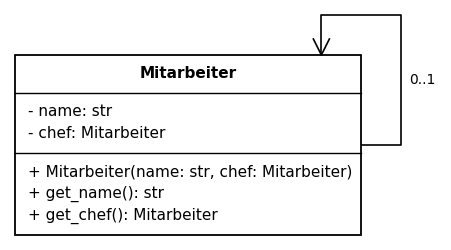



In [ ]:
class Mitarbeiter:
    def __init__(self, name, chef=None):
        self.__name = name
        self.__chef = chef

    def get_name(self):
        return self.__name

    def get_chef(self):
        return self.__chef

boss = Mitarbeiter('Frau König')
leiter = Mitarbeiter('Herr Graf', boss)
azubi = Mitarbeiter('Ali', leiter)
print(azubi.get_chef().get_name())
m = azubi
while m is not None:
    print(m.get_name())
    m = m.get_chef()

#### Aufgabe 6.1

Ergänze die Klasse um `ebene()`: die Anzahl der Chefs über dem Mitarbeiter (die Chefin ganz oben hat Ebene 0). Gib die Ebene von König, Ali und Bea aus.

**Erwartete Ausgabe:**
```
0 2 3
```

In [ ]:
class Mitarbeiter:
    def __init__(self, name, chef=None):
        self.__name = name
        self.__chef = chef

    def get_name(self):
        return self.__name

    def get_chef(self):
        return self.__chef
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Mitarbeiter:
    def __init__(self, name, chef=None):
        self.__name = name
        self.__chef = chef

    def get_name(self):
        return self.__name

    def get_chef(self):
        return self.__chef


    def ebene(self):
        anzahl = 0
        m = self.__chef
        while m is not None:
            anzahl += 1
            m = m.get_chef()
        return anzahl

koenig = Mitarbeiter('Frau König')
graf = Mitarbeiter('Herr Graf', koenig)
sahin = Mitarbeiter('Frau Sahin', koenig)
ali = Mitarbeiter('Ali', graf)
bea = Mitarbeiter('Bea', ali)
cem = Mitarbeiter('Cem', sahin)
print(koenig.ebene(), ali.ebene(), bea.ebene())
```

</details>

#### Aufgabe 6.2

Ergänze die Klasse um `oberster_chef()`, die den Mitarbeiter ganz oben zurückgibt (bei der Chefin selbst sich selbst). Gib den Namen für Bea und für König aus.

**Erwartete Ausgabe:**
```
Frau König
Frau König
```

In [ ]:
class Mitarbeiter:
    def __init__(self, name, chef=None):
        self.__name = name
        self.__chef = chef

    def get_name(self):
        return self.__name

    def get_chef(self):
        return self.__chef
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Mitarbeiter:
    def __init__(self, name, chef=None):
        self.__name = name
        self.__chef = chef

    def get_name(self):
        return self.__name

    def get_chef(self):
        return self.__chef


    def oberster_chef(self):
        m = self
        while m.get_chef() is not None:
            m = m.get_chef()
        return m

koenig = Mitarbeiter('Frau König')
graf = Mitarbeiter('Herr Graf', koenig)
sahin = Mitarbeiter('Frau Sahin', koenig)
ali = Mitarbeiter('Ali', graf)
bea = Mitarbeiter('Bea', ali)
cem = Mitarbeiter('Cem', sahin)
print(bea.oberster_chef().get_name())
print(koenig.oberster_chef().get_name())
```

</details>

#### Aufgabe 6.3

Ergänze die Klasse um `dienstweg()`, die die Namen vom Mitarbeiter bis nach oben als Text mit ` → ` dazwischen zurückgibt. Gib den Dienstweg von Bea und von Cem aus.

**Erwartete Ausgabe:**
```
Bea → Ali → Herr Graf → Frau König
Cem → Frau Sahin → Frau König
```

In [ ]:
class Mitarbeiter:
    def __init__(self, name, chef=None):
        self.__name = name
        self.__chef = chef

    def get_name(self):
        return self.__name

    def get_chef(self):
        return self.__chef
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Mitarbeiter:
    def __init__(self, name, chef=None):
        self.__name = name
        self.__chef = chef

    def get_name(self):
        return self.__name

    def get_chef(self):
        return self.__chef


    def dienstweg(self):
        namen = []
        m = self
        while m is not None:
            namen.append(m.get_name())
            m = m.get_chef()
        return ' → '.join(namen)

koenig = Mitarbeiter('Frau König')
graf = Mitarbeiter('Herr Graf', koenig)
sahin = Mitarbeiter('Frau Sahin', koenig)
ali = Mitarbeiter('Ali', graf)
bea = Mitarbeiter('Bea', ali)
cem = Mitarbeiter('Cem', sahin)
print(bea.dienstweg())
print(cem.dienstweg())
```

</details>

#### Aufgabe 6.4

Schreibe eine Funktion `ist_vorgesetzt(a, b)`, die `True` zurückgibt, wenn `a` (direkt oder weiter oben) Chef von `b` ist. Gib das für (König, Bea), (Graf, Cem)
und (Ali, Bea) aus.

**Erwartete Ausgabe:**
```
True
False
True
```

In [ ]:
class Mitarbeiter:
    def __init__(self, name, chef=None):
        self.__name = name
        self.__chef = chef

    def get_name(self):
        return self.__name

    def get_chef(self):
        return self.__chef

koenig = Mitarbeiter('Frau König')
graf = Mitarbeiter('Herr Graf', koenig)
sahin = Mitarbeiter('Frau Sahin', koenig)
ali = Mitarbeiter('Ali', graf)
bea = Mitarbeiter('Bea', ali)
cem = Mitarbeiter('Cem', sahin)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Mitarbeiter:
    def __init__(self, name, chef=None):
        self.__name = name
        self.__chef = chef

    def get_name(self):
        return self.__name

    def get_chef(self):
        return self.__chef

koenig = Mitarbeiter('Frau König')
graf = Mitarbeiter('Herr Graf', koenig)
sahin = Mitarbeiter('Frau Sahin', koenig)
ali = Mitarbeiter('Ali', graf)
bea = Mitarbeiter('Bea', ali)
cem = Mitarbeiter('Cem', sahin)

def ist_vorgesetzt(a, b):
    m = b.get_chef()
    while m is not None:
        if m is a:
            return True
        m = m.get_chef()
    return False

print(ist_vorgesetzt(koenig, bea))
print(ist_vorgesetzt(graf, cem))
print(ist_vorgesetzt(ali, bea))
```

</details>

#### Ein Zug aus Waggons

Ein Waggon kennt den **nächsten** Waggon (0..1). Die Lok kennt nur den ersten Waggon. Will man alle Waggons besuchen, startet man beim ersten und geht
immer zum nächsten, bis `None` kommt.

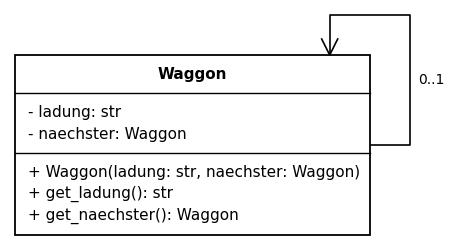



In [ ]:
class Waggon:
    def __init__(self, ladung, naechster=None):
        self.__ladung = ladung
        self.__naechster = naechster

    def get_ladung(self):
        return self.__ladung

    def get_naechster(self):
        return self.__naechster

w3 = Waggon('Kohle')
w2 = Waggon('Holz', w3)
w1 = Waggon('Autos', w2)
w = w1
while w is not None:
    print(w.get_ladung())
    w = w.get_naechster()

#### Aufgabe 6.5

Ergänze die Klasse `Zug` um `laenge()`, die die Anzahl der Waggons zurückgibt, und `gewicht()`, die die Summe der Tonnen zurückgibt. Gib beides aus.

**Erwartete Ausgabe:**
```
4 145
```

In [ ]:
class Waggon:
    def __init__(self, ladung, tonnen, naechster=None):
        self.__ladung = ladung
        self.__tonnen = tonnen
        self.__naechster = naechster

    def get_ladung(self):
        return self.__ladung

    def get_tonnen(self):
        return self.__tonnen

    def get_naechster(self):
        return self.__naechster

class Zug:
    def __init__(self, erster):
        self.__erster = erster
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Waggon:
    def __init__(self, ladung, tonnen, naechster=None):
        self.__ladung = ladung
        self.__tonnen = tonnen
        self.__naechster = naechster

    def get_ladung(self):
        return self.__ladung

    def get_tonnen(self):
        return self.__tonnen

    def get_naechster(self):
        return self.__naechster

class Zug:
    def __init__(self, erster):
        self.__erster = erster


    def laenge(self):
        anzahl = 0
        w = self.__erster
        while w is not None:
            anzahl += 1
            w = w.get_naechster()
        return anzahl

    def gewicht(self):
        summe = 0
        w = self.__erster
        while w is not None:
            summe += w.get_tonnen()
            w = w.get_naechster()
        return summe

zug = Zug(Waggon('Autos', 20, Waggon('Holz', 35, Waggon('Kohle', 60, Waggon('Holz', 30)))))
print(zug.laenge(), zug.gewicht())
```

</details>

#### Aufgabe 6.6

Ergänze die Klasse `Zug` um `ladungen()`, die die Ladungen ohne Doppelte in der Reihenfolge ihres ersten Auftretens als Liste zurückgibt, und `letzter()`, die die Ladung des letzten Waggons zurückgibt.

**Erwartete Ausgabe:**
```
['Autos', 'Holz', 'Kohle']
Holz
```

In [ ]:
class Waggon:
    def __init__(self, ladung, tonnen, naechster=None):
        self.__ladung = ladung
        self.__tonnen = tonnen
        self.__naechster = naechster

    def get_ladung(self):
        return self.__ladung

    def get_tonnen(self):
        return self.__tonnen

    def get_naechster(self):
        return self.__naechster

class Zug:
    def __init__(self, erster):
        self.__erster = erster
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Waggon:
    def __init__(self, ladung, tonnen, naechster=None):
        self.__ladung = ladung
        self.__tonnen = tonnen
        self.__naechster = naechster

    def get_ladung(self):
        return self.__ladung

    def get_tonnen(self):
        return self.__tonnen

    def get_naechster(self):
        return self.__naechster

class Zug:
    def __init__(self, erster):
        self.__erster = erster


    def ladungen(self):
        ergebnis = []
        w = self.__erster
        while w is not None:
            if w.get_ladung() not in ergebnis:
                ergebnis.append(w.get_ladung())
            w = w.get_naechster()
        return ergebnis

    def letzter(self):
        w = self.__erster
        while w.get_naechster() is not None:
            w = w.get_naechster()
        return w.get_ladung()

zug = Zug(Waggon('Autos', 20, Waggon('Holz', 35, Waggon('Kohle', 60, Waggon('Holz', 30)))))
print(zug.ladungen())
print(zug.letzter())
```

</details>

#### Aufgabe 6.7

Ergänze die Klasse `Zug` um `__str__`, die den Zug als `Lok-[Autos]-[Holz]-...` zurückgibt. Gib den Zug aus.

**Erwartete Ausgabe:**
```
Lok-[Autos]-[Holz]-[Kohle]-[Holz]
```

In [ ]:
class Waggon:
    def __init__(self, ladung, tonnen, naechster=None):
        self.__ladung = ladung
        self.__tonnen = tonnen
        self.__naechster = naechster

    def get_ladung(self):
        return self.__ladung

    def get_tonnen(self):
        return self.__tonnen

    def get_naechster(self):
        return self.__naechster

class Zug:
    def __init__(self, erster):
        self.__erster = erster
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Waggon:
    def __init__(self, ladung, tonnen, naechster=None):
        self.__ladung = ladung
        self.__tonnen = tonnen
        self.__naechster = naechster

    def get_ladung(self):
        return self.__ladung

    def get_tonnen(self):
        return self.__tonnen

    def get_naechster(self):
        return self.__naechster

class Zug:
    def __init__(self, erster):
        self.__erster = erster


    def __str__(self):
        text = 'Lok'
        w = self.__erster
        while w is not None:
            text += f'-[{w.get_ladung()}]'
            w = w.get_naechster()
        return text

zug = Zug(Waggon('Autos', 20, Waggon('Holz', 35, Waggon('Kohle', 60, Waggon('Holz', 30)))))
print(zug)
```

</details>

#### Stammbaum

Eine Person kennt ihre Mutter und ihren Vater (jeweils 0..1, weil man nicht alle Vorfahren kennt). Um **alle** Vorfahren zu finden, ruft eine Methode
sich für Mutter und Vater **selbst** auf (Rekursion, siehe Notebook über Funktionen).

Im Diagramm sind die beiden Beziehungen `mutter` und `vater` zu einem Pfeil zusammengefasst: Eine Person kennt bis zu 2 Personen, also `0..2`.

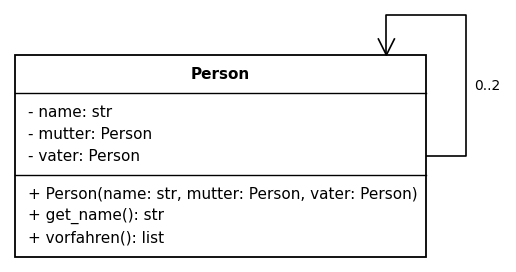



In [ ]:
class Person:
    def __init__(self, name, mutter=None, vater=None):
        self.__name = name
        self.__mutter = mutter
        self.__vater = vater

    def get_name(self):
        return self.__name

    def vorfahren(self):
        ergebnis = []
        for elternteil in [self.__mutter, self.__vater]:
            if elternteil is not None:
                ergebnis.append(elternteil.get_name())
                ergebnis += elternteil.vorfahren()
        return ergebnis

oma = Person('Oma Erika')
opa = Person('Opa Hans')
mama = Person('Mama', oma, opa)
papa = Person('Papa')
kind = Person('Lea', mama, papa)
print(kind.vorfahren())

#### Aufgabe 6.8

Ergänze die Klasse `Person` um `anzahl_vorfahren()` (rekursiv). Gib sie für Lea, Mama und Erika aus.

**Erwartete Ausgabe:**
```
5 2 0
```

In [ ]:
class Person:
    def __init__(self, name, mutter=None, vater=None):
        self.__name = name
        self.__mutter = mutter
        self.__vater = vater

    def get_name(self):
        return self.__name
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Person:
    def __init__(self, name, mutter=None, vater=None):
        self.__name = name
        self.__mutter = mutter
        self.__vater = vater

    def get_name(self):
        return self.__name


    def anzahl_vorfahren(self):
        anzahl = 0
        for e in [self.__mutter, self.__vater]:
            if e is not None:
                anzahl += 1 + e.anzahl_vorfahren()
        return anzahl

erika = Person('Erika')
hans = Person('Hans')
gerda = Person('Gerda')
mama = Person('Mama', erika, hans)
papa = Person('Papa', gerda)
lea = Person('Lea', mama, papa)
tim = Person('Tim', mama, papa)
print(lea.anzahl_vorfahren(), mama.anzahl_vorfahren(), erika.anzahl_vorfahren())
```

</details>

#### Aufgabe 6.9

Ergänze die Klasse `Person` um `get_mutter()`, `get_vater()` und `ist_geschwister(other)`: `True`, wenn beide dieselbe (bekannte) Mutter oder denselben (bekannten) Vater haben. Teste mit Lea und Tim, Lea und Mama.

**Erwartete Ausgabe:**
```
True
False
```

In [ ]:
class Person:
    def __init__(self, name, mutter=None, vater=None):
        self.__name = name
        self.__mutter = mutter
        self.__vater = vater

    def get_name(self):
        return self.__name
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Person:
    def __init__(self, name, mutter=None, vater=None):
        self.__name = name
        self.__mutter = mutter
        self.__vater = vater

    def get_name(self):
        return self.__name


    def get_mutter(self):
        return self.__mutter

    def get_vater(self):
        return self.__vater

    def ist_geschwister(self, other):
        if self.__mutter is not None and self.__mutter is other.get_mutter():
            return True
        return self.__vater is not None and self.__vater is other.get_vater()

erika = Person('Erika')
hans = Person('Hans')
gerda = Person('Gerda')
mama = Person('Mama', erika, hans)
papa = Person('Papa', gerda)
lea = Person('Lea', mama, papa)
tim = Person('Tim', mama, papa)
print(lea.ist_geschwister(tim))
print(lea.ist_geschwister(mama))
```

</details>

#### Aufgabe 6.10

Ergänze die Klasse `Person` um `generationen()`: Wie viele Generationen von Vorfahren sind bekannt? Ohne Eltern 0, sonst 1 plus das Maximum der Eltern. Gib den Wert für Lea, Papa und Hans aus.

**Erwartete Ausgabe:**
```
2 1 0
```

In [ ]:
class Person:
    def __init__(self, name, mutter=None, vater=None):
        self.__name = name
        self.__mutter = mutter
        self.__vater = vater

    def get_name(self):
        return self.__name
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Person:
    def __init__(self, name, mutter=None, vater=None):
        self.__name = name
        self.__mutter = mutter
        self.__vater = vater

    def get_name(self):
        return self.__name


    def generationen(self):
        tiefe = 0
        for e in [self.__mutter, self.__vater]:
            if e is not None:
                tiefe = max(tiefe, 1 + e.generationen())
        return tiefe

erika = Person('Erika')
hans = Person('Hans')
gerda = Person('Gerda')
mama = Person('Mama', erika, hans)
papa = Person('Papa', gerda)
lea = Person('Lea', mama, papa)
tim = Person('Tim', mama, papa)
print(lea.generationen(), papa.generationen(), hans.generationen())
```

</details>

#### Viele Objekte der eigenen Klasse: Freunde

Eine Person kann beliebig viele Freunde haben (0..*), die selbst Personen sind. Freundschaft gilt in beide Richtungen: `befreunden()` trägt beide Seiten ein.

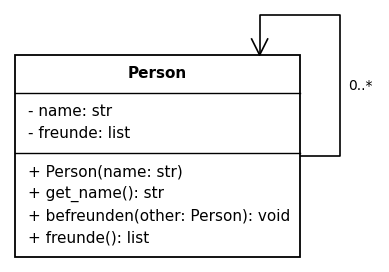



In [ ]:
class Person:
    def __init__(self, name):
        self.__name = name
        self.__freunde = []

    def get_name(self):
        return self.__name

    def befreunden(self, other):
        self.__freunde.append(other)
        other.__freunde.append(self)

    def freunde(self):
        namen = []
        for f in self.__freunde:
            namen.append(f.get_name())
        return namen

ali = Person('Ali')
bea = Person('Bea')
cem = Person('Cem')
ali.befreunden(bea)
cem.befreunden(ali)
print(ali.freunde(), bea.freunde())

#### Aufgabe 6.11

Ergänze die Klasse `Person` um `gemeinsame_freunde(other)`, die die Namen der Freunde zurückgibt, die beide haben (sortiert). Gib sie für Ali und Bea und für Ali und Dana aus.

**Erwartete Ausgabe:**
```
['Cem']
['Bea']
```

In [ ]:
class Person:
    def __init__(self, name):
        self.__name = name
        self.__freunde = []

    def get_name(self):
        return self.__name

    def get_freunde(self):
        return list(self.__freunde)

    def befreunden(self, other):
        self.__freunde.append(other)
        other.__freunde.append(self)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Person:
    def __init__(self, name):
        self.__name = name
        self.__freunde = []

    def get_name(self):
        return self.__name

    def get_freunde(self):
        return list(self.__freunde)

    def befreunden(self, other):
        self.__freunde.append(other)
        other.__freunde.append(self)


    def gemeinsame_freunde(self, other):
        namen = []
        for f in self.__freunde:
            if f in other.get_freunde():
                namen.append(f.get_name())
        return sorted(namen)

ali, bea, cem, dana, emil = Person('Ali'), Person('Bea'), Person('Cem'), Person('Dana'), Person('Emil')
ali.befreunden(bea)
ali.befreunden(cem)
bea.befreunden(cem)
bea.befreunden(dana)
dana.befreunden(emil)
print(ali.gemeinsame_freunde(bea))
print(ali.gemeinsame_freunde(dana))
```

</details>

#### Aufgabe 6.12

Ergänze die Klasse `Person` um `freunde_von_freunden()`: die sortierten Namen aller Personen, die mit einem Freund befreundet sind, aber weder man selbst noch schon ein Freund sind. Gib sie für Ali und für Emil aus.

**Erwartete Ausgabe:**
```
['Dana']
['Bea']
```

In [ ]:
class Person:
    def __init__(self, name):
        self.__name = name
        self.__freunde = []

    def get_name(self):
        return self.__name

    def get_freunde(self):
        return list(self.__freunde)

    def befreunden(self, other):
        self.__freunde.append(other)
        other.__freunde.append(self)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Person:
    def __init__(self, name):
        self.__name = name
        self.__freunde = []

    def get_name(self):
        return self.__name

    def get_freunde(self):
        return list(self.__freunde)

    def befreunden(self, other):
        self.__freunde.append(other)
        other.__freunde.append(self)


    def freunde_von_freunden(self):
        namen = []
        for f in self.__freunde:
            for ff in f.get_freunde():
                if ff is not self and ff not in self.__freunde and ff.get_name() not in namen:
                    namen.append(ff.get_name())
        return sorted(namen)

ali, bea, cem, dana, emil = Person('Ali'), Person('Bea'), Person('Cem'), Person('Dana'), Person('Emil')
ali.befreunden(bea)
ali.befreunden(cem)
bea.befreunden(cem)
bea.befreunden(dana)
dana.befreunden(emil)
print(ali.freunde_von_freunden())
print(emil.freunde_von_freunden())
```

</details>

#### Aufgabe 6.13

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Knoten:
    def __init__(self, wert, weiter=None):
        self.wert = wert
        self.weiter = weiter

k = Knoten(1, Knoten(2, Knoten(3)))
summe = 0
while k is not None:
    summe += k.wert
    k = k.weiter
print(summe)

#### Aufgabe 6.14

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Mitarbeiter:
    def __init__(self, name, chef=None):
        self.name = name
        self.chef = chef

a = Mitarbeiter('A')
b = Mitarbeiter('B', a)
c = Mitarbeiter('C', b)
print(c.chef.chef.name)
b.chef = None
print(c.chef.chef)

## 7. Gemischte Übungen

#### Aufgabe 7.1

Setze die Klassen um. Eine Bestellung gehört zu genau einem Kunden und enthält Artikel mit Preisen. Ein Kunde kennt seine Bestellungen (ungerichtet).
`Kunde.neue_bestellung()` erzeugt eine Bestellung für diesen Kunden, hängt sie an seine Liste und gibt sie zurück. `Kunde.umsatz()` ist die Summe aller
Bestellungen. Lege für Ali zwei Bestellungen an: (Buch 12.99, Stift 1.50) und (Rucksack 34.90). Gib die Anzahl der Bestellungen und den Umsatz mit zwei Nachkommastellen aus,
danach über die erste Bestellung den Namen des Kunden.

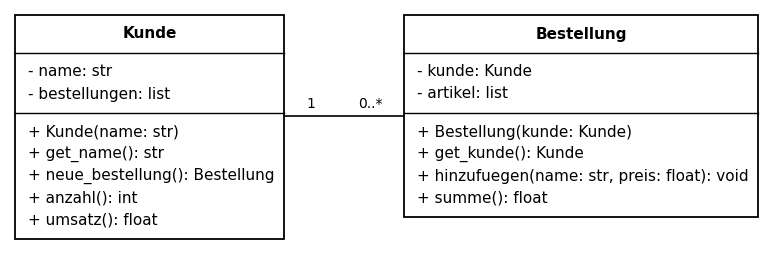



**Erwartete Ausgabe:**
```
2
49.39
Ali
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Bestellung:
    def __init__(self, kunde):
        self.__kunde = kunde
        self.__artikel = []

    def get_kunde(self):
        return self.__kunde

    def hinzufuegen(self, name, preis):
        self.__artikel.append((name, preis))

    def summe(self):
        s = 0
        for name, preis in self.__artikel:
            s += preis
        return s

class Kunde:
    def __init__(self, name):
        self.__name = name
        self.__bestellungen = []

    def get_name(self):
        return self.__name

    def neue_bestellung(self):
        b = Bestellung(self)
        self.__bestellungen.append(b)
        return b

    def anzahl(self):
        return len(self.__bestellungen)

    def umsatz(self):
        s = 0
        for b in self.__bestellungen:
            s += b.summe()
        return s

ali = Kunde('Ali')
b1 = ali.neue_bestellung()
b1.hinzufuegen('Buch', 12.99)
b1.hinzufuegen('Stift', 1.50)
b2 = ali.neue_bestellung()
b2.hinzufuegen('Rucksack', 34.90)
print(ali.anzahl())
print(f'{ali.umsatz():.2f}')
print(b1.get_kunde().get_name())
```

</details>

#### Aufgabe 7.2

Setze die Klassen um. Ein Spielfeld kennt seine Spielfiguren (0..*), jede Figur steht auf einem Feld (Zahl 0 bis `laenge - 1`). `ziehen(figur, augen)` setzt
eine Figur weiter, aber nicht über das Ende hinaus. Steht dort schon eine **andere** Figur, wird diese zurück auf 0 geschickt („Mensch ärgere dich nicht“).
Führe die Züge aus `zuege` aus und gib danach jede Figur mit Name und Feld aus.

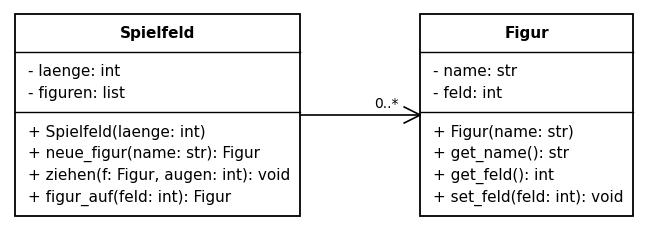



**Erwartete Ausgabe:**
```
rot 0
blau 9
gelb 6
```

In [ ]:
zuege = [('rot', 4), ('blau', 6), ('rot', 2), ('gelb', 3), ('blau', 9), ('gelb', 3)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
zuege = [('rot', 4), ('blau', 6), ('rot', 2), ('gelb', 3), ('blau', 9), ('gelb', 3)]
class Figur:
    def __init__(self, name):
        self.__name = name
        self.__feld = 0

    def get_name(self):
        return self.__name

    def get_feld(self):
        return self.__feld

    def set_feld(self, feld):
        self.__feld = feld

class Spielfeld:
    def __init__(self, laenge):
        self.__laenge = laenge
        self.__figuren = []

    def neue_figur(self, name):
        f = Figur(name)
        self.__figuren.append(f)
        return f

    def figur_auf(self, feld):
        for f in self.__figuren:
            if f.get_feld() == feld:
                return f
        return None

    def ziehen(self, f, augen):
        ziel = min(f.get_feld() + augen, self.__laenge - 1)
        andere = self.figur_auf(ziel)
        if andere is not None and andere is not f:
            andere.set_feld(0)
        f.set_feld(ziel)

feld = Spielfeld(12)
figuren = {}
for name in ['rot', 'blau', 'gelb']:
    figuren[name] = feld.neue_figur(name)
for name, augen in zuege:
    feld.ziehen(figuren[name], augen)
for name in ['rot', 'blau', 'gelb']:
    print(name, figuren[name].get_feld())
```

</details>

#### Aufgabe 7.3

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Raum:
    def __init__(self, name):
        self.name = name
        self.ausgang = None

flur = Raum('Flur')
kueche = Raum('Küche')
bad = Raum('Bad')
flur.ausgang = kueche
kueche.ausgang = bad
bad.ausgang = flur
r = flur
for i in range(5):
    r = r.ausgang
print(r.name)